# Treinamento, validação e teste independentes por derivação — QRS/PTB-XL

**Objetivo:** construir **12 experimentos independentes**, um para cada derivação (`I`, `II`, `III`, `aVR`, `aVL`, `aVF`, `V1`–`V6`), utilizando **somente registros com extração QRS `COMPLETA` naquela derivação**. Não se combinam derivações em um mesmo modelo.

**Divisão planejada:** folds oficiais da PTB-XL **1–6 (treino), 7–8 (validação), 9–10 (teste)**. Isso corresponde a 60/20/20 dos *folds*, não garante exatamente 60/20/20 dos ECGs após a seleção. A divisão é por paciente, preservando a independência dos conjuntos. O conjunto de teste permanece reservado até a avaliação final.

**Tarefa inicial:** classificação binária **0 = Normal/Sinusal** versus **1 = Anormal**. As subcategorias `1.1_MI` a `1.6_RHYTHM` são reunidas apenas para **definir o rótulo binário**, não para juntar sinais de diferentes derivações. ECGs presentes em mais de uma subcategoria anormal são contabilizados uma única vez por derivação. O notebook não treina classificação multirrótulo.

**Critérios de elegibilidade:** (1) não estar entre os 445 IDs excluídos; (2) possuir `instancias.csv`; (3) ter ao menos um candidato QRS; (4) todos os candidatos da derivação terem `situacao == ESTIMATIVA_EXPLORATORIA`; (5) o CSV da derivação existir e ter recortes íntegros. A denominação `COMPLETA` se refere à extração computacional, não à validação clínica.

**Importante:** nenhuma pasta de origem é modificada. As saídas vão para `Experimentos-QRS-60-20-20/`.
**Modelo exportado:** `Experimentos-QRS-60-20-20/<derivação>/modelo_RandomForest_<derivação>.pkl` (serialização com `joblib`). Derivações sem exemplos completos são ignoradas sem interromper a execução.


## 1. Bibliotecas e configuração

In [1]:
# Caso necessário, instale uma única vez:
# %pip install pandas numpy scikit-learn matplotlib joblib tqdm

from pathlib import Path
from collections import Counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score)
import joblib

RAIZ = Path.cwd()  # ajuste se o notebook não estiver na raiz do projeto
PASTA_QRS = RAIZ / 'Recortes-QRS'
PASTA_RESULTADOS = RAIZ / 'resultados'
SAIDA = RAIZ / 'Experimentos-QRS-60-20-20'
DERIVACOES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']
FOLDS = {'treino': [1,2,3,4,5,6], 'validacao': [7,8], 'teste': [9,10]}
SEMENTE = 42
N_ARVORES = 200
EXECUTAR_TREINAMENTO = True  # False para gerar apenas os conjuntos CSV

assert PASTA_QRS.is_dir(), f'Pasta não encontrada: {PASTA_QRS}'
SAIDA.mkdir(parents=True, exist_ok=True)
print('Origem:', PASTA_QRS)
print('Destino:', SAIDA)


c:\Users\Matheus\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Origem: c:\Users\Matheus\Documents\Detctor-automatizado-QRS\Recortes-QRS
Destino: c:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20


## 2. Metadados da PTB-XL e exclusões obrigatórias

In [2]:
def localizar_unico(padrao, pastas):
    arquivos = []
    for pasta in pastas:
        if pasta.is_dir():
            arquivos.extend(pasta.glob(padrao))
    arquivos = sorted({p.resolve() for p in arquivos})
    if len(arquivos) != 1:
        raise RuntimeError(f'Esperado um único arquivo {padrao}; encontrados: {arquivos}. Ajuste os caminhos.')
    return arquivos[0]

ARQUIVO_PTB = localizar_unico('ptbxl_database.csv', [RAIZ, RAIZ / 'PTB-XL'])
ARQUIVO_EXCLUSAO = localizar_unico('instancias_NORM_e_anormal_juntos*.csv', [PASTA_RESULTADOS])
ptb = pd.read_csv(ARQUIVO_PTB, usecols=['ecg_id','patient_id','strat_fold'])
ptb[['ecg_id','patient_id','strat_fold']] = ptb[['ecg_id','patient_id','strat_fold']].apply(pd.to_numeric, errors='raise')
ptb['ecg_id'] = ptb.ecg_id.astype(int)
ptb['patient_id'] = ptb.patient_id.astype(int)
ptb['strat_fold'] = ptb.strat_fold.astype(int)
assert ptb.ecg_id.is_unique, 'ecg_id duplicado nos metadados.'
assert ptb.strat_fold.between(1,10).all(), 'strat_fold fora de 1–10.'

excluidos = set(pd.to_numeric(pd.read_csv(ARQUIVO_EXCLUSAO)['ecg_id'], errors='raise').astype(int))
assert len(excluidos) == 445, f'Esperados 445 IDs excluídos; encontrados {len(excluidos)}.'
assert ptb.groupby('patient_id').strat_fold.nunique().max() == 1, 'Há pacientes distribuídos em folds distintos.'
print('PTB-XL:', len(ptb), 'registros; excluídos:', len(excluidos))
print('Folds:', FOLDS)


PTB-XL: 21799 registros; excluídos: 445
Folds: {'treino': [1, 2, 3, 4, 5, 6], 'validacao': [7, 8], 'teste': [9, 10]}


## 3. Inventário de ECGs e avaliação de completude por derivação

A leitura de `instancias.csv` determina a situação de **cada derivação**. Um ECG completo em V1 pode ser parcial em V2. Os CSVs de recortes são verificados antes da inclusão definitiva.

In [3]:
def classe_da_pasta(pasta):
    partes = pasta.relative_to(PASTA_QRS).parts
    if not partes:
        return None
    if partes[0] == '0':
        return 0
    if partes[0] == '1' or any(p.startswith('1.') and p.split('_')[0] in
                                 {'1.1','1.2','1.3','1.4','1.5','1.6'} for p in partes):
        return 1
    return None

def id_da_pasta(pasta, dados):
    if 'ecg_id' in dados.columns:
        valores = pd.to_numeric(dados.ecg_id, errors='coerce').dropna().unique()
        if len(valores) == 1:
            return int(valores[0])
    if pasta.name.isdigit():
        return int(pasta.name)
    return None

inventario = []
metas = list(PASTA_QRS.rglob('instancias.csv'))
print('Arquivos instancias.csv encontrados:', len(metas))
for arquivo in tqdm(metas, desc='Inventariando ECGs'):
    pasta = arquivo.parent
    rotulo = classe_da_pasta(pasta)
    if rotulo is None:
        continue
    try:
        dados = pd.read_csv(arquivo, usecols=['ecg_id','derivacao','batimento','situacao'])
        dados['derivacao'] = dados['derivacao'].astype(str).str.strip()
        eid = id_da_pasta(pasta, dados)
        if eid is None or eid in excluidos:
            continue
        for derivacao in DERIVACOES:
            linhas = dados.loc[dados.derivacao.eq(derivacao)]
            candidatos = int(linhas.batimento.notna().sum())
            validos = int((linhas.batimento.notna() & linhas.situacao.eq('ESTIMATIVA_EXPLORATORIA')).sum())
            status = ('COMPLETA' if candidatos > 0 and validos == candidatos
                      else 'PARCIAL' if validos > 0 else 'SEM_RECORTES_VALIDOS')
            inventario.append({'ecg_id':eid, 'rotulo':rotulo, 'derivacao':derivacao,
                               'candidatos':candidatos, 'validos':validos,
                               'situacao':status, 'pasta':str(pasta)})
    except Exception as e:
        print('Falha ao ler:', arquivo, '|', str(e))

inv = pd.DataFrame(inventario)
if inv.empty:
    raise RuntimeError('Nenhum ECG foi encontrado. Confira a pasta Recortes-QRS.')
print(inv.groupby(['derivacao','situacao']).size().unstack(fill_value=0).reindex(DERIVACOES))


Arquivos instancias.csv encontrados: 35235


Inventariando ECGs: 100%|██████████| 35235/35235 [05:16<00:00, 111.22it/s]


situacao   COMPLETA  PARCIAL  SEM_RECORTES_VALIDOS
derivacao                                         
I             27424     7810                     1
II            27514     7721                     0
III           27394     7840                     1
aVR               0        0                 35235
aVL               0        0                 35235
aVF               0        0                 35235
V1            27490     7745                     0
V2            27518     7717                     0
V3            27447     7784                     4
V4            27563     7672                     0
V5            27483     7749                     3
V6            27422     7804                     9


## 4. Seleção dos completos, deduplicação e integridade dos CSVs

Para evitar que um ECG presente em várias subcategorias anormais seja contado várias vezes, mantém-se **um registro por `ecg_id` e derivação**. Rótulos conflitantes geram erro. A integridade é checada usando as amostras registradas para cada batimento.

In [4]:
def csv_integro(pasta, derivacao, candidatos):
    caminho = Path(pasta) / f'{derivacao}_QRS.csv'
    if not caminho.is_file():
        return False
    try:
        x = pd.read_csv(caminho, usecols=['batimento','amostra_qrs','amostra_original','amplitude_mV'])
        if x.empty or x[['batimento','amostra_qrs','amostra_original','amplitude_mV']].isna().any().any():
            return False
        if x.batimento.nunique() != candidatos:
            return False
        for _, g in x.groupby('batimento'):
            a = np.sort(g.amostra_qrs.to_numpy(dtype=int))
            orig = np.sort(g.amostra_original.to_numpy(dtype=int))
            if len(a) < 3 or not np.array_equal(a, np.arange(len(a))):
                return False
            if not np.array_equal(orig, np.arange(orig[0], orig[0] + len(orig))):
                return False
        return True
    except (OSError, ValueError, KeyError, pd.errors.ParserError):
        return False

candidatos = inv[inv.situacao.eq('COMPLETA')].copy()
conflitos = candidatos.groupby(['derivacao','ecg_id']).rotulo.nunique()
assert conflitos.max() <= 1, 'Conflito de rótulos entre cópias do mesmo ECG.'
candidatos = candidatos.sort_values(['derivacao','ecg_id','pasta']).drop_duplicates(['derivacao','ecg_id'])

integridade = []
for r in tqdm(candidatos.itertuples(index=False), total=len(candidatos), desc='Conferindo recortes'):
    integridade.append(csv_integro(r.pasta, r.derivacao, r.candidatos))
candidatos['integro'] = integridade
print('Recortes completos e íntegros:', sum(integridade), '/', len(integridade))
print('Recortes completos com falha de integridade:', len(integridade) - sum(integridade))
selecionados = candidatos.loc[candidatos.integro].copy()
selecionados = selecionados.merge(ptb, on='ecg_id', how='inner', validate='many_to_one')
assert not selecionados.ecg_id.isin(excluidos).any()
assert not selecionados.duplicated(['derivacao','ecg_id']).any()

def atribuir_particao(fold):
    for nome, folds in FOLDS.items():
        if fold in folds:
            return nome
    raise ValueError(f'Fold inválido: {fold}')
selecionados['particao'] = selecionados.strat_fold.map(atribuir_particao)
print(selecionados.groupby(['derivacao','particao']).size().unstack(fill_value=0).reindex(DERIVACOES))


Conferindo recortes: 100%|██████████| 150037/150037 [09:44<00:00, 256.77it/s] 


Recortes completos e íntegros: 150037 / 150037
Recortes completos com falha de integridade: 0
particao    teste   treino  validacao
derivacao                            
I          3343.0  10026.0     3273.0
II         3352.0  10051.0     3291.0
III        3326.0   9969.0     3296.0
aVR           NaN      NaN        NaN
aVL           NaN      NaN        NaN
aVF           NaN      NaN        NaN
V1         3357.0  10025.0     3314.0
V2         3364.0  10024.0     3305.0
V3         3362.0  10003.0     3285.0
V4         3356.0  10069.0     3303.0
V5         3351.0  10054.0     3284.0
V6         3342.0  10039.0     3273.0


## 5. Auditoria dos conjuntos e exportação de manifestos 60/20/20

Os conjuntos são gerados **por derivação**, sem combinar sinais. As proporções observadas são apresentadas para cada derivação. Nenhum paciente aparece em mais de uma partição, inclusive quando são considerados os 12 experimentos.

In [5]:
# Verificação global de ausência de vazamento por paciente.
assert selecionados.groupby('patient_id').particao.nunique().max() == 1, 'Vazamento entre partições!'
resumo = []
for derivacao in DERIVACOES:
    d = selecionados[selecionados.derivacao.eq(derivacao)].copy()
    destino = SAIDA / derivacao
    destino.mkdir(parents=True, exist_ok=True)
    total = len(d)
    for particao in ['treino','validacao','teste']:
        sub = d.loc[d.particao.eq(particao)].copy()
        sub.to_csv(destino / f'{particao}.csv', index=False)
        resumo.append({'derivacao':derivacao,'particao':particao,
                       'ecgs':len(sub),'pacientes':sub.patient_id.nunique(),
                       'percentual':round(100*len(sub)/total,2) if total else 0,
                       'normais':int((sub.rotulo==0).sum()),
                       'anormais':int((sub.rotulo==1).sum())})
resumo_df = pd.DataFrame(resumo)
resumo_df.to_csv(SAIDA / 'resumo_particoes.csv', index=False)
selecionados.to_csv(SAIDA / 'manifesto_geral_auditoria.csv', index=False)
print(resumo_df.to_string(index=False))


derivacao  particao  ecgs  pacientes  percentual  normais  anormais
        I    treino 10026       8898       60.25     3852      6174
        I validacao  3273       2903       19.67     1279      1994
        I     teste  3343       3007       20.09     1220      2123
       II    treino 10051       8905       60.21     3849      6202
       II validacao  3291       2918       19.71     1281      2010
       II     teste  3352       3019       20.08     1224      2128
      III    treino  9969       8857       60.09     3817      6152
      III validacao  3296       2931       19.87     1284      2012
      III     teste  3326       3003       20.05     1216      2110
      aVR    treino     0          0        0.00        0         0
      aVR validacao     0          0        0.00        0         0
      aVR     teste     0          0        0.00        0         0
      aVL    treino     0          0        0.00        0         0
      aVL validacao     0          0        0.00

## 6. Gráfico das proporções reais por derivação

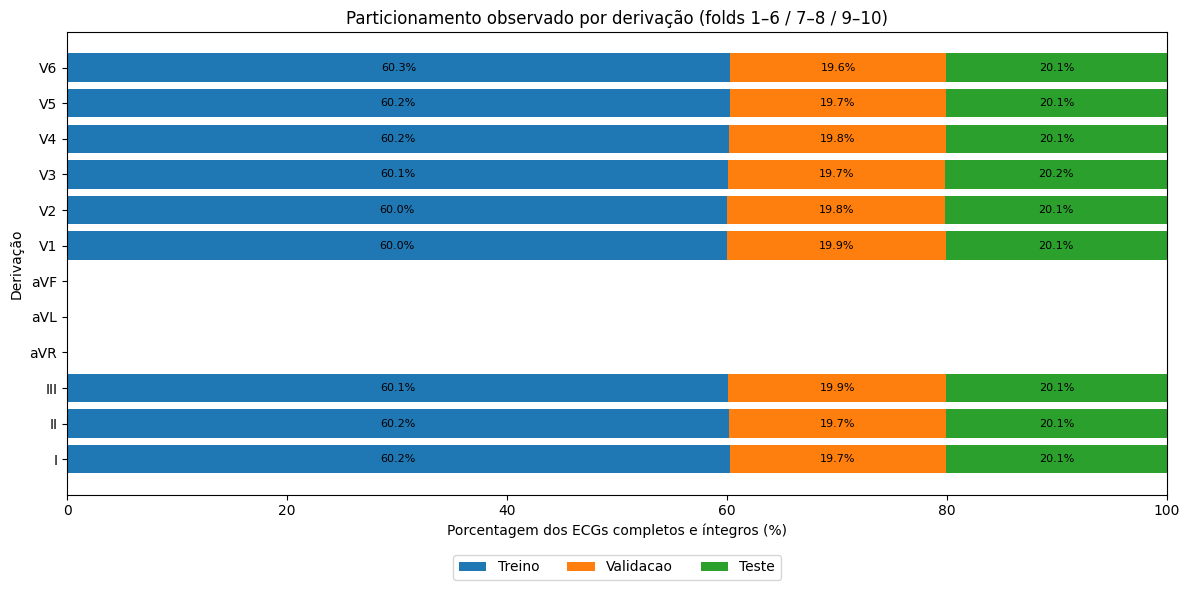

In [6]:
p = resumo_df.pivot(index='derivacao',columns='particao',values='percentual').reindex(DERIVACOES)
fig, ax = plt.subplots(figsize=(12,6))
base = np.zeros(len(p))
for nome in ['treino','validacao','teste']:
    vals = p[nome].to_numpy()
    barras = ax.barh(p.index, vals, left=base, label=nome.capitalize())
    for i,v in enumerate(vals):
        if v >= 5:
            ax.text(base[i]+v/2,i,f'{v:.1f}%',ha='center',va='center',fontsize=8)
    base += vals
ax.set(xlim=(0,100),xlabel='Porcentagem dos ECGs completos e íntegros (%)',
       ylabel='Derivação',title='Particionamento observado por derivação (folds 1–6 / 7–8 / 9–10)')
ax.legend(ncol=3,loc='lower center',bbox_to_anchor=(.5,-.20))
plt.tight_layout()
fig.savefig(SAIDA/'proporcoes_por_derivacao.png',dpi=200,bbox_inches='tight')
plt.show()


## 7. Extração de atributos QRS por derivação

**Modelo inicial de referência (baseline):** atributos estatísticos dos recortes QRS **da própria derivação**, agregados por ECG. São utilizados número de batimentos, duração QRS e medidas de amplitude/forma. **Nenhum sinal de outra derivação é usado.** A extração de atributos não utiliza o rótulo diagnóstico. Para trabalhos futuros, os CSVs de recortes podem alimentar arquiteturas que utilizem a forma de onda diretamente.

In [7]:
ATRIBUTOS = [
    'n_qrs','duracao_media','duracao_std','duracao_mediana','duracao_min','duracao_max',
    'qrs_alargado_frac','amplitude_media','amplitude_std','amplitude_min',
    'amplitude_max','amplitude_pico_abs_media','amplitude_ptp_media',
    'energia_media','amplitude_mediana','amplitude_abs_media'
]

def atributos_ecg(pasta, derivacao):
    arq = Path(pasta) / f'{derivacao}_QRS.csv'
    x = pd.read_csv(arq, usecols=['batimento','amplitude_mV','duracao_qrs_ms','qrs_alargado'])
    a = pd.to_numeric(x.amplitude_mV, errors='coerce').to_numpy(dtype=float)
    dur = pd.to_numeric(x.duracao_qrs_ms, errors='coerce')
    larg = x.qrs_alargado.astype(str).str.lower().eq('true')
    por_batimento = x.groupby('batimento').amplitude_mV.agg(['min','max'])
    ptp = (por_batimento['max'] - por_batimento['min']).to_numpy(dtype=float)
    return {
        'n_qrs':int(x.batimento.nunique()),
        'duracao_media':float(dur.mean()),
        'duracao_std':float(dur.std(ddof=0)),
        'duracao_mediana':float(dur.median()),
        'duracao_min':float(dur.min()),
        'duracao_max':float(dur.max()),
        'qrs_alargado_frac':float(larg.mean()),
        'amplitude_media':float(np.mean(a)),
        'amplitude_std':float(np.std(a)),
        'amplitude_min':float(np.min(a)),
        'amplitude_max':float(np.max(a)),
        'amplitude_pico_abs_media':float(np.mean(np.maximum(abs(por_batimento['min']),abs(por_batimento['max'])))),
        'amplitude_ptp_media':float(np.mean(ptp)),
        'energia_media':float(np.mean(a**2)),
        'amplitude_mediana':float(np.median(a)),
        'amplitude_abs_media':float(np.mean(abs(a))),
    }

def criar_tabela_atributos(derivacao):
    d = selecionados[selecionados.derivacao.eq(derivacao)]
    linhas = []
    for r in tqdm(d.itertuples(index=False),total=len(d),desc=f'Atributos {derivacao}'):
        try:
            at = atributos_ecg(r.pasta,derivacao)
            linhas.append({'ecg_id':r.ecg_id,'patient_id':r.patient_id,'rotulo':r.rotulo,
                           'particao':r.particao,**at})
        except Exception as e:
            raise RuntimeError(f'Falha em {derivacao}, ECG {r.ecg_id}: {e}') from e
    # Mesmo sem registros, manter o esquema para evitar AttributeError.
    colunas = ['ecg_id','patient_id','rotulo','particao',*ATRIBUTOS]
    tabela = pd.DataFrame(linhas, columns=colunas)
    tabela.to_csv(SAIDA/derivacao/'atributos_qrs.csv',index=False)
    return tabela


## 8. Treinar 12 modelos independentes

Cada modelo usa apenas a derivação correspondente. O treino utiliza exclusivamente os folds 1–6; a validação utiliza 7–8; e o teste utiliza 9–10. O teste é avaliado uma única vez, após o ajuste. Não são feitas escolhas de hiperparâmetros com base no teste. Para evitar conclusões artificiais, derivações com uma única classe em treino/validação/teste são sinalizadas e não treinadas.

In [8]:
metricas = []
modelos_exportados = []

for derivacao in DERIVACOES:
    print("\n" + "="*65 + f"\nDERIVAÇÃO {derivacao}\n" + "="*65)
    pasta_saida = SAIDA / derivacao
    pasta_saida.mkdir(parents=True, exist_ok=True)

    if not EXECUTAR_TREINAMENTO:
        print("Treinamento desabilitado: defina EXECUTAR_TREINAMENTO = True.")
        metricas.append({"derivacao": derivacao, "situacao": "TREINAMENTO_DESABILITADO"})
        continue

    tabela = criar_tabela_atributos(derivacao)
    if tabela.empty:
        print("Sem registros COMPLETA e íntegros.")
        metricas.append({"derivacao": derivacao, "situacao": "SEM_REGISTROS_COMPLETOS"})
        continue

    grupos = {
        nome: tabela.loc[tabela["particao"].eq(nome)].copy()
        for nome in ["treino", "validacao", "teste"]
    }
    for nome, dados in grupos.items():
        print(nome, len(dados), "classes:", dados["rotulo"].value_counts().to_dict())

    treino = grupos["treino"]
    if treino.empty or treino["rotulo"].nunique() < 2:
        print("Não é possível treinar Random Forest: treino vazio ou com apenas uma classe.")
        metricas.append({"derivacao": derivacao, "situacao": "TREINO_CLASSES_INSUFICIENTES"})
        continue

    # Treinamento e exportação não dependem de haver validação/teste disponíveis.
    modelo = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("classificador", RandomForestClassifier(
            n_estimators=N_ARVORES, random_state=SEMENTE,
            n_jobs=-1, class_weight="balanced_subsample"
        ))
    ])
    modelo.fit(treino[ATRIBUTOS], treino["rotulo"])

    caminho_modelo = pasta_saida / f"modelo_RandomForest_{derivacao}.pkl"
    joblib.dump(modelo, caminho_modelo)
    # Conferência real: existe, não está vazio e pode ser reaberto.
    assert caminho_modelo.is_file() and caminho_modelo.stat().st_size > 0, (
        f"Arquivo PKL não foi gravado: {caminho_modelo}"
    )
    modelo_salvo = joblib.load(caminho_modelo)
    assert list(modelo_salvo.classes_) == list(modelo.classes_)
    print(f"PKL SALVO E VERIFICADO: {caminho_modelo.resolve()}")
    modelos_exportados.append({
        "derivacao": derivacao,
        "algoritmo": "RandomForest",
        "arquivo_pkl": str(caminho_modelo.resolve()),
        "tamanho_bytes": caminho_modelo.stat().st_size,
        "ecgs_treino": len(treino),
    })

    for nome in ["validacao", "teste"]:
        dados = grupos[nome]
        if dados.empty:
            print(f"{nome}: sem dados; modelo PKL já foi salvo.")
            metricas.append({
                "derivacao": derivacao,
                "situacao": "PARTICAO_VAZIA",
                "particao": nome,
                "n": 0,
            })
            continue

        pred = modelo.predict(dados[ATRIBUTOS])
        idx_anormal = list(modelo.classes_).index(1)
        prob = modelo.predict_proba(dados[ATRIBUTOS])[:, idx_anormal]
        auc = roc_auc_score(dados["rotulo"], prob) if dados["rotulo"].nunique() == 2 else np.nan
        met = {
            "derivacao": derivacao,
            "situacao": "AVALIADO",
            "particao": nome,
            "n": len(dados),
            "acuracia": accuracy_score(dados["rotulo"], pred),
            "acuracia_balanceada": balanced_accuracy_score(dados["rotulo"], pred),
            "f1_macro": f1_score(dados["rotulo"], pred, average="macro", zero_division=0),
            "f1_anormal": f1_score(dados["rotulo"], pred, pos_label=1, zero_division=0),
            "roc_auc": auc,
        }
        metricas.append(met)

        pd.DataFrame({
            "ecg_id": dados["ecg_id"],
            "patient_id": dados["patient_id"],
            "rotulo_real": dados["rotulo"],
            "predicao": pred,
            "prob_anormal": prob,
        }).to_csv(pasta_saida / f"predicoes_{nome}.csv", index=False)

        (pasta_saida / f"relatorio_{nome}.txt").write_text(
            classification_report(
                dados["rotulo"], pred, labels=[0, 1],
                target_names=["Normal", "Anormal"], zero_division=0
            ), encoding="utf-8"
        )
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ConfusionMatrixDisplay(
            confusion_matrix(dados["rotulo"], pred, labels=[0, 1]),
            display_labels=["Normal", "Anormal"]
        ).plot(ax=ax, cmap="Greys", colorbar=False)
        ax.set_title(f"{derivacao} — {nome}")
        fig.tight_layout()
        fig.savefig(pasta_saida / f"matriz_confusao_{nome}.png", dpi=180)
        plt.close(fig)
        print(f"{nome}: acurácia={met['acuracia']:.4f}, F1 macro={met['f1_macro']:.4f}")

metricas_df = pd.DataFrame(metricas, columns=[
    "derivacao", "situacao", "particao", "n", "acuracia",
    "acuracia_balanceada", "f1_macro", "f1_anormal", "roc_auc"
])
metricas_df.to_csv(SAIDA / "metricas_por_derivacao.csv", index=False)

exportados_df = pd.DataFrame(modelos_exportados, columns=[
    "derivacao", "algoritmo", "arquivo_pkl", "tamanho_bytes", "ecgs_treino"
])
exportados_df.to_csv(SAIDA / "modelos_pkl_exportados.csv", index=False)
print(f"\nTOTAL DE MODELOS PKL EXPORTADOS: {len(modelos_exportados)}/{len(DERIVACOES)}")
display(exportados_df)
display(metricas_df)



DERIVAÇÃO I


Atributos I: 100%|██████████| 16642/16642 [01:04<00:00, 257.73it/s]


treino 10026 classes: {1: 6174, 0: 3852}
validacao 3273 classes: {1: 1994, 0: 1279}
teste 3343 classes: {1: 2123, 0: 1220}
PKL SALVO E VERIFICADO: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20\I\modelo_RandomForest_I.pkl
validacao: acurácia=0.6688, F1 macro=0.6465
teste: acurácia=0.6614, F1 macro=0.6385

DERIVAÇÃO II


Atributos II: 100%|██████████| 16694/16694 [01:07<00:00, 249.02it/s]


treino 10051 classes: {1: 6202, 0: 3849}
validacao 3291 classes: {1: 2010, 0: 1281}
teste 3352 classes: {1: 2128, 0: 1224}
PKL SALVO E VERIFICADO: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20\II\modelo_RandomForest_II.pkl
validacao: acurácia=0.7153, F1 macro=0.6991
teste: acurácia=0.6954, F1 macro=0.6768

DERIVAÇÃO III


Atributos III: 100%|██████████| 16591/16591 [00:45<00:00, 364.20it/s]


... (17 outputs left out)

Atributos V6: 100%|██████████| 16654/16654 [01:06<00:00, 248.58it/s]


treino 10039 classes: {1: 6182, 0: 3857}
validacao 3273 classes: {1: 1990, 0: 1283}
teste 3342 classes: {1: 2116, 0: 1226}
PKL SALVO E VERIFICADO: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20\V6\modelo_RandomForest_V6.pkl
validacao: acurácia=0.7030, F1 macro=0.6867
teste: acurácia=0.6888, F1 macro=0.6718

TOTAL DE MODELOS PKL EXPORTADOS: 9/12


,derivacao,algoritmo,arquivo_pkl,tamanho_bytes,ecgs_treino
0,I,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,58171695,10026
1,II,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,54326415,10051
2,III,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,54762095,9969
3,V1,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,58252335,10025
4,V2,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,59353135,10024
5,V3,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,58423055,10003
6,V4,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,57139055,10069
7,V5,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,56087375,10054
8,V6,RandomForest,C:\Users\Matheus\Documents\Detctor-automatizad...,55982095,10039


,derivacao,situacao,particao,n,acuracia,acuracia_balanceada,f1_macro,f1_anormal,roc_auc
0,I,AVALIADO,validacao,3273.0,0.668805,0.644638,0.646451,0.735352,0.743593
1,I,AVALIADO,teste,3343.0,0.661382,0.640135,0.638504,0.729446,0.731587
2,II,AVALIADO,validacao,3291.0,0.715284,0.698115,0.699066,0.768927,0.802730
3,II,AVALIADO,teste,3352.0,0.695406,0.680104,0.676763,0.754390,0.766007
4,III,AVALIADO,validacao,3296.0,0.706311,0.681526,0.684533,0.767420,0.769173
5,III,AVALIADO,teste,3326.0,0.688815,0.663624,0.663934,0.755377,0.742076
6,aVR,SEM_REGISTROS_COMPLETOS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,aVL,SEM_REGISTROS_COMPLETOS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,aVF,SEM_REGISTROS_COMPLETOS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,V1,AVALIADO,validacao,3314.0,0.653591,0.628939,0.630408,0.722973,0.726461


### Verificação final dos arquivos `.pkl`

A célula seguinte lista os modelos realmente gravados na pasta de saída. Uma derivação sem exemplos suficientes para treinamento não gera modelo.


In [9]:
arquivos_pkl = sorted(SAIDA.rglob('modelo_RandomForest_*.pkl'))
print('Pasta de saída:', SAIDA.resolve())
print('Total de arquivos .pkl encontrados:', len(arquivos_pkl))
for arquivo in arquivos_pkl:
    print(f'{arquivo.relative_to(SAIDA)} — {arquivo.stat().st_size:,} bytes')
if not arquivos_pkl:
    print('Nenhum PKL encontrado. Consulte metricas_por_derivacao.csv e verifique EXECUTAR_TREINAMENTO.')


Pasta de saída: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20
Total de arquivos .pkl encontrados: 9
I\modelo_RandomForest_I.pkl — 58,171,695 bytes
II\modelo_RandomForest_II.pkl — 54,326,415 bytes
III\modelo_RandomForest_III.pkl — 54,762,095 bytes
V1\modelo_RandomForest_V1.pkl — 58,252,335 bytes
V2\modelo_RandomForest_V2.pkl — 59,353,135 bytes
V3\modelo_RandomForest_V3.pkl — 58,423,055 bytes
V4\modelo_RandomForest_V4.pkl — 57,139,055 bytes
V5\modelo_RandomForest_V5.pkl — 56,087,375 bytes
V6\modelo_RandomForest_V6.pkl — 55,982,095 bytes


## 9. Comparação dos resultados dos 12 experimentos

A comparação abaixo apresenta resultados **por derivação**. Como o filtro `COMPLETA` pode produzir populações diferentes, diferenças de desempenho não devem ser atribuídas exclusivamente à derivação. Uma análise adicional com a interseção de ECGs completos em todas as derivações pode ser planejada, mas **não é realizada neste notebook**.

,n,acuracia,acuracia_balanceada,f1_macro,roc_auc
derivacao,,,,,
I,3343.0,0.661382,0.640135,0.638504,0.731587
II,3352.0,0.695406,0.680104,0.676763,0.766007
III,3326.0,0.688815,0.663624,0.663934,0.742076
aVR,NaN,NaN,NaN,NaN,NaN
aVL,NaN,NaN,NaN,NaN,NaN
aVF,NaN,NaN,NaN,NaN,NaN
V1,3357.0,0.636580,0.605095,0.605733,0.696672
V2,3364.0,0.653983,0.618532,0.620148,0.712489
V3,3362.0,0.654670,0.616353,0.618361,0.706506


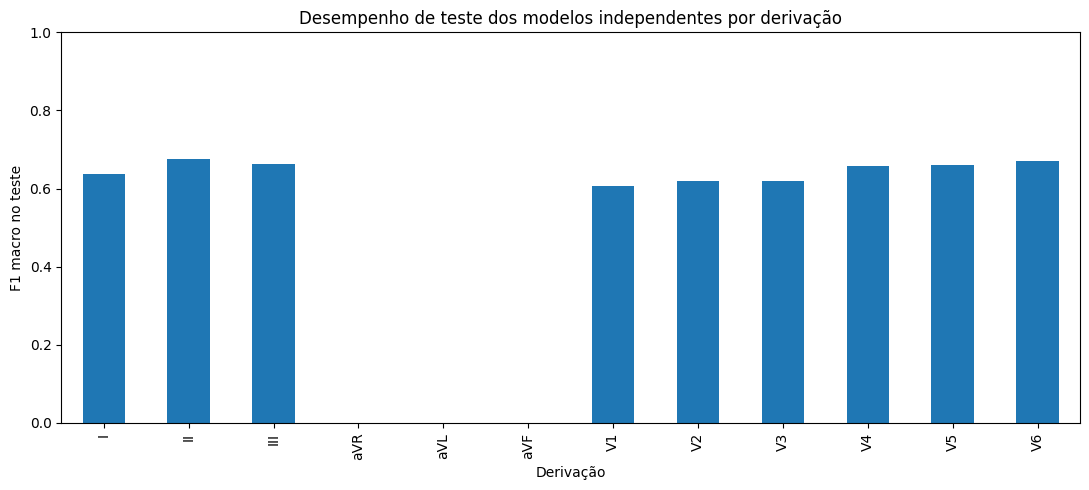

In [10]:
if not metricas_df.empty and 'particao' in metricas_df.columns and (metricas_df['particao'] == 'teste').any():
    teste = metricas_df[metricas_df.particao.eq('teste')].set_index('derivacao').reindex(DERIVACOES)
    display(teste[['n','acuracia','acuracia_balanceada','f1_macro','roc_auc']])
    fig,ax=plt.subplots(figsize=(11,5))
    teste['f1_macro'].plot.bar(ax=ax)
    ax.set(xlabel='Derivação',ylabel='F1 macro no teste',ylim=(0,1),
           title='Desempenho de teste dos modelos independentes por derivação')
    fig.tight_layout()
    fig.savefig(SAIDA/'comparacao_f1_teste.png',dpi=200)
    plt.show()
else:
    print('Sem resultados de treinamento para comparar.')


## 10. Arquivos gerados e observações metodológicas

- `Experimentos-QRS-60-20-20/<derivação>/treino.csv`, `validacao.csv`, `teste.csv`: manifestos de **ECGs completos e íntegros** daquela derivação, sem mistura de canais.
- `atributos_qrs.csv`: atributos extraídos **exclusivamente** do CSV QRS daquela derivação.
- `modelo_RandomForest_<derivação>.pkl`: modelo binário independente da derivação.
- `predicoes_validacao.csv` e `predicoes_teste.csv`, relatórios e matrizes de confusão.
- `resumo_particoes.csv`, `metricas_por_derivacao.csv` e gráficos gerais: somente **comparações de resultados**, sem fusão de sinais.

**Limitações:** (i) a definição de `COMPLETA` depende dos candidatos detectados e não comprova que todos os batimentos reais foram encontrados; (ii) a estimativa de limites QRS não foi validada clinicamente; (iii) os recortes possuem comprimentos variáveis e o baseline usa atributos agregados, não sequências brutas; (iv) os folds oficiais garantem independência por paciente, mas as proporções de ECGs filtrados podem diferir de 60/20/20; (v) o conjunto de ECGs pode variar entre derivações; (vi) os rótulos são diagnósticos do ECG completo, não necessariamente do QRS isolado.


## 11. Análises adicionais — sem alterar o treinamento original

As células a seguir são **somente acréscimos** ao notebook original. Reutilizam os arquivos `predicoes_validacao.csv`, `predicoes_teste.csv` e `modelo_RandomForest_<derivacao>.pkl` já exportados, sem retreinar ou modificar modelos. Geram gráficos individuais e comparativos, tabelas e relatórios. Resultados ausentes são registrados sem interromper as outras derivações. Execute após as células anteriores (ou execute estas células com `SAIDA` e `DERIVACOES` definidos).


In [11]:
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
    balanced_accuracy_score, roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib

PASTA_ANALISES = SAIDA / 'Analises_Adicionais'
PASTA_ANALISES.mkdir(parents=True, exist_ok=True)

# Não altera nenhum resultado, CSV ou modelo produzido pelas células anteriores.
def ler_predicoes(derivacao, particao):
    arq = SAIDA / derivacao / f'predicoes_{particao}.csv'
    if not arq.is_file():
        return None
    try:
        df = pd.read_csv(arq)
    except (OSError, pd.errors.EmptyDataError) as exc:
        print(f'Não foi possível ler {arq}: {exc}')
        return None
    campos = {'rotulo_real', 'predicao', 'prob_anormal'}
    if not campos.issubset(df.columns):
        print(f'Colunas ausentes em {arq}: {sorted(campos - set(df.columns))}')
        return None
    df = df.copy()
    for campo in campos:
        df[campo] = pd.to_numeric(df[campo], errors='coerce')
    df = df.dropna(subset=list(campos))
    df = df[df['rotulo_real'].isin([0,1]) & df['predicao'].isin([0,1])]
    df = df[df['prob_anormal'].between(0,1)]
    return df if not df.empty else None

print('Análises adicionais serão gravadas em:', PASTA_ANALISES.resolve())


Análises adicionais serão gravadas em: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20\Analises_Adicionais


### 11.1. Métricas detalhadas por derivação e partição

Inclui precisão, sensibilidade (recall), especificidade, F1 de cada classe, F1 macro, acurácia, acurácia balanceada, ROC-AUC e Average Precision. As métricas de ROC-AUC e AP ficam indefinidas quando existe apenas uma classe real.


In [12]:
linhas_detalhadas = []
for derivacao in DERIVACOES:
    for particao in ('validacao', 'teste'):
        df = ler_predicoes(derivacao, particao)
        if df is None:
            continue
        y = df['rotulo_real'].astype(int).to_numpy()
        yp = df['predicao'].astype(int).to_numpy()
        prob = df['prob_anormal'].to_numpy()
        tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0,1]).ravel()
        tem_ambas = len(np.unique(y)) == 2
        linhas_detalhadas.append({
            'derivacao':derivacao, 'particao':particao, 'n':len(df),
            'n_normal':int((y==0).sum()), 'n_anormal':int((y==1).sum()),
            'tn':int(tn), 'fp':int(fp), 'fn':int(fn), 'tp':int(tp),
            'acuracia':accuracy_score(y,yp),
            'acuracia_balanceada':balanced_accuracy_score(y,yp),
            'precisao_anormal':precision_score(y,yp,pos_label=1,zero_division=0),
            'recall_anormal':recall_score(y,yp,pos_label=1,zero_division=0),
            'especificidade':tn/(tn+fp) if (tn+fp)>0 else np.nan,
            'f1_normal':f1_score(y,yp,pos_label=0,zero_division=0),
            'f1_anormal':f1_score(y,yp,pos_label=1,zero_division=0),
            'f1_macro':f1_score(y,yp,average='macro',zero_division=0),
            'roc_auc':roc_auc_score(y,prob) if tem_ambas else np.nan,
            'average_precision':average_precision_score(y,prob) if tem_ambas else np.nan,
        })
metricas_adicionais = pd.DataFrame(linhas_detalhadas)
metricas_adicionais.to_csv(PASTA_ANALISES/'metricas_detalhadas_validacao_teste.csv',index=False)
print('Avaliações disponíveis:',len(metricas_adicionais))
display(metricas_adicionais)


Avaliações disponíveis: 18


,derivacao,particao,n,n_normal,n_anormal,tn,fp,fn,tp,acuracia,acuracia_balanceada,precisao_anormal,recall_anormal,especificidade,f1_normal,f1_anormal,f1_macro,roc_auc,average_precision
0,I,validacao,3273,1279,1994,683,596,488,1506,0.668805,0.644638,0.716461,0.755266,0.534011,0.557551,0.735352,0.646451,0.743593,0.841276
1,I,teste,3343,1220,2123,685,535,597,1526,0.661382,0.640135,0.740417,0.718794,0.561475,0.547562,0.729446,0.638504,0.731587,0.845734
2,II,validacao,3291,1281,2010,795,486,451,1559,0.715284,0.698115,0.762347,0.775622,0.620609,0.629205,0.768927,0.699066,0.802730,0.876938
3,II,teste,3352,1224,2128,763,461,560,1568,0.695406,0.680104,0.772794,0.736842,0.623366,0.599136,0.754390,0.676763,0.766007,0.865114
4,III,validacao,3296,1284,2012,731,553,415,1597,0.706311,0.681526,0.742791,0.793738,0.569315,0.601646,0.767420,0.684533,0.769173,0.849838
5,III,teste,3326,1216,2110,693,523,512,1598,0.688815,0.663624,0.753418,0.757346,0.569901,0.572491,0.755377,0.663934,0.742076,0.842614
6,V1,validacao,3314,1292,2022,668,624,524,1498,0.653591,0.628939,0.705938,0.740851,0.517028,0.537842,0.722973,0.630408,0.726461,0.829924
7,V1,teste,3357,1228,2129,599,629,591,1538,0.636580,0.605095,0.709737,0.722405,0.487785,0.495451,0.716015,0.605733,0.696672,0.821086
8,V2,validacao,3305,1284,2021,658,626,422,1599,0.682905,0.651827,0.718652,0.791192,0.512461,0.556684,0.753179,0.654932,0.746589,0.839869
9,V2,teste,3364,1226,2138,598,628,536,1602,0.653983,0.618532,0.718386,0.749298,0.487765,0.506780,0.733516,0.620148,0.712489,0.829797


### 11.2. Gráficos individuais: ROC, precisão–recall, probabilidades, matriz de confusão normalizada e importância dos atributos

Cada derivação terá sua própria pasta em `Analises_Adicionais/<derivação>/`. Não são criados gráficos de ROC ou precisão–recall se a partição não tiver as duas classes reais. A importância dos atributos é extraída dos modelos `.pkl` existentes, sem alterá-los.


In [13]:
for derivacao in DERIVACOES:
    pasta = PASTA_ANALISES / derivacao
    pasta.mkdir(parents=True, exist_ok=True)
    for particao in ('validacao','teste'):
        df = ler_predicoes(derivacao,particao)
        if df is None:
            continue
        y = df['rotulo_real'].astype(int).to_numpy()
        yp = df['predicao'].astype(int).to_numpy()
        prob = df['prob_anormal'].to_numpy()
        cm = confusion_matrix(y,yp,labels=[0,1],normalize='true')
        fig,ax=plt.subplots(figsize=(5,4))
        ConfusionMatrixDisplay(cm,display_labels=['Normal','Anormal']).plot(ax=ax,cmap='Blues',values_format='.2f',colorbar=False)
        ax.set_title(f'{derivacao} — {particao} — matriz normalizada')
        fig.tight_layout();fig.savefig(pasta/f'matriz_confusao_normalizada_{particao}.png',dpi=200);plt.close(fig)

        fig,ax=plt.subplots(figsize=(6,4))
        ax.hist(prob[y==0],bins=20,alpha=.6,label='Normal (real)')
        ax.hist(prob[y==1],bins=20,alpha=.6,label='Anormal (real)')
        ax.axvline(.5,linestyle='--',color='black',label='Limiar 0,5')
        ax.set(xlabel='Probabilidade prevista de Anormal',ylabel='Quantidade',title=f'{derivacao} — {particao} — distribuição de probabilidades')
        ax.legend();fig.tight_layout();fig.savefig(pasta/f'distribuicao_probabilidades_{particao}.png',dpi=200);plt.close(fig)

        if len(np.unique(y))==2:
            fpr,tpr,_=roc_curve(y,prob)
            auc=roc_auc_score(y,prob)
            fig,ax=plt.subplots(figsize=(5.5,4.5))
            ax.plot(fpr,tpr,label=f'AUC = {auc:.3f}')
            ax.plot([0,1],[0,1],'--',color='gray',label='Aleatório')
            ax.set(xlabel='Taxa de falsos positivos',ylabel='Sensibilidade',title=f'{derivacao} — {particao} — curva ROC')
            ax.legend();fig.tight_layout();fig.savefig(pasta/f'curva_roc_{particao}.png',dpi=200);plt.close(fig)

            precisao,recall,_=precision_recall_curve(y,prob)
            ap=average_precision_score(y,prob)
            fig,ax=plt.subplots(figsize=(5.5,4.5))
            ax.plot(recall,precisao,label=f'AP = {ap:.3f}')
            ax.axhline(np.mean(y),linestyle='--',color='gray',label='Prevalência Anormal')
            ax.set(xlabel='Recall (Anormal)',ylabel='Precisão (Anormal)',title=f'{derivacao} — {particao} — curva precisão–recall')
            ax.legend();fig.tight_layout();fig.savefig(pasta/f'curva_precisao_recall_{particao}.png',dpi=200);plt.close(fig)

    caminho_pkl = SAIDA / derivacao / f'modelo_RandomForest_{derivacao}.pkl'
    if caminho_pkl.is_file():
        try:
            modelo=joblib.load(caminho_pkl)
            importancias=modelo.named_steps['classificador'].feature_importances_
            nomes=list(ATRIBUTOS)
            if len(importancias)!=len(nomes):
                nomes=[f'atributo_{i}' for i in range(len(importancias))]
            imp=pd.DataFrame({'atributo':nomes,'importancia':importancias}).sort_values('importancia',ascending=False)
            imp.to_csv(pasta/'importancia_atributos.csv',index=False)
            fig,ax=plt.subplots(figsize=(8,max(4,len(imp)*.32)))
            ax.barh(imp['atributo'][::-1],imp['importancia'][::-1])
            ax.set(xlabel='Importância por redução de impureza',title=f'{derivacao} — Random Forest — importância dos atributos')
            fig.tight_layout();fig.savefig(pasta/'importancia_atributos.png',dpi=200);plt.close(fig)
        except (OSError,KeyError,AttributeError,ValueError) as exc:
            print(f'Não foi possível gerar importâncias para {derivacao}: {exc}')
print('Gráficos individuais concluídos em:',PASTA_ANALISES)


Gráficos individuais concluídos em: c:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20\Analises_Adicionais


### 11.3. Comparações gerais — todas as métricas, não apenas F1

Exporta gráficos de barras de cada métrica, comparação ROC e precisão–recall, matrizes de confusão em painel, distribuição de classes e mapa de calor. As comparações consideram apenas derivações com predições de teste disponíveis.


In [14]:
pasta_geral=PASTA_ANALISES/'Comparacoes_Gerais'
pasta_geral.mkdir(parents=True,exist_ok=True)
if metricas_adicionais.empty or not (metricas_adicionais['particao']=='teste').any():
    print('Sem predições de teste disponíveis para comparações.')
else:
    teste_ad=metricas_adicionais.loc[metricas_adicionais['particao'].eq('teste')].set_index('derivacao').reindex(DERIVACOES)
    colunas_metricas=['acuracia','acuracia_balanceada','precisao_anormal','recall_anormal','especificidade','f1_normal','f1_anormal','f1_macro','roc_auc','average_precision']
    for metrica in colunas_metricas:
        valores=teste_ad[metrica].dropna()
        if valores.empty:continue
        fig,ax=plt.subplots(figsize=(11,5))
        valores.plot.bar(ax=ax)
        ax.set(xlabel='Derivação',ylabel=metrica.replace('_',' ').title(),ylim=(0,1),title=f'Comparação por derivação — {metrica} — teste')
        fig.tight_layout();fig.savefig(pasta_geral/f'comparacao_{metrica}_teste.png',dpi=200);plt.close(fig)
    mapa=teste_ad[colunas_metricas].dropna(how='all')
    if not mapa.empty:
        fig,ax=plt.subplots(figsize=(12,6))
        im=ax.imshow(mapa.to_numpy(dtype=float),vmin=0,vmax=1,aspect='auto',cmap='viridis')
        ax.set_xticks(np.arange(len(mapa.columns)),labels=[x.replace('_',' ') for x in mapa.columns],rotation=45,ha='right')
        ax.set_yticks(np.arange(len(mapa.index)),labels=mapa.index)
        fig.colorbar(im,ax=ax,label='Valor da métrica')
        ax.set_title('Comparação geral das métricas no teste')
        fig.tight_layout();fig.savefig(pasta_geral/'mapa_calor_metricas_teste.png',dpi=200);plt.close(fig)

    fig,ax=plt.subplots(figsize=(10,5))
    contagens=teste_ad[['n_normal','n_anormal']].dropna(how='all').fillna(0)
    contagens.plot.bar(stacked=True,ax=ax)
    ax.set(xlabel='Derivação',ylabel='ECGs no teste',title='Distribuição das classes reais por derivação')
    fig.tight_layout();fig.savefig(pasta_geral/'comparacao_distribuicao_classes_teste.png',dpi=200);plt.close(fig)

    fig_roc,ax_roc=plt.subplots(figsize=(7,6))
    fig_pr,ax_pr=plt.subplots(figsize=(7,6))
    curvas=0
    for derivacao in DERIVACOES:
        df=ler_predicoes(derivacao,'teste')
        if df is None or df['rotulo_real'].nunique()<2:continue
        y=df['rotulo_real'].astype(int).to_numpy();prob=df['prob_anormal'].to_numpy()
        fpr,tpr,_=roc_curve(y,prob)
        prec,rec,_=precision_recall_curve(y,prob)
        ax_roc.plot(fpr,tpr,label=f'{derivacao} (AUC {roc_auc_score(y,prob):.2f})')
        ax_pr.plot(rec,prec,label=f'{derivacao} (AP {average_precision_score(y,prob):.2f})')
        curvas+=1
    if curvas:
        ax_roc.plot([0,1],[0,1],'--',color='gray')
        ax_roc.set(xlabel='Taxa de falsos positivos',ylabel='Sensibilidade',title='Curvas ROC — teste — derivações independentes')
        ax_roc.legend(fontsize=8,ncol=2);fig_roc.tight_layout();fig_roc.savefig(pasta_geral/'comparacao_curvas_roc_teste.png',dpi=200)
        ax_pr.set(xlabel='Recall (Anormal)',ylabel='Precisão (Anormal)',title='Curvas precisão–recall — teste')
        ax_pr.legend(fontsize=8,ncol=2);fig_pr.tight_layout();fig_pr.savefig(pasta_geral/'comparacao_curvas_precisao_recall_teste.png',dpi=200)
    plt.close(fig_roc);plt.close(fig_pr)

    existentes=[d for d in DERIVACOES if ler_predicoes(d,'teste') is not None]
    if existentes:
        ncol=3;nlin=(len(existentes)+ncol-1)//ncol
        fig,axes=plt.subplots(nlin,ncol,figsize=(12,3.7*nlin),squeeze=False)
        for ax in axes.ravel():ax.axis('off')
        for ax,derivacao in zip(axes.ravel(),existentes):
            df=ler_predicoes(derivacao,'teste')
            cm=confusion_matrix(df['rotulo_real'],df['predicao'],labels=[0,1])
            ax.axis('on')
            ConfusionMatrixDisplay(cm,display_labels=['Normal','Anormal']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
            ax.set_title(derivacao)
        fig.suptitle('Matrizes de confusão — teste — por derivação')
        fig.tight_layout();fig.savefig(pasta_geral/'comparacao_matrizes_confusao_teste.png',dpi=200);plt.close(fig)
    teste_ad.reset_index().to_csv(pasta_geral/'comparacao_metricas_teste.csv',index=False)
    print('Gráficos comparativos exportados:',pasta_geral.resolve())


Gráficos comparativos exportados: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Experimentos-QRS-60-20-20\Analises_Adicionais\Comparacoes_Gerais


### 11.4. Inventário final de arquivos gerados

Esta verificação mostra quantos arquivos de imagem e CSV foram realmente produzidos. Nenhuma análise adicional altera os modelos `.pkl`.


In [15]:
arquivos_novos=sorted(p for p in PASTA_ANALISES.rglob('*') if p.is_file())
print('Total de arquivos de análises adicionais:',len(arquivos_novos))
print('Imagens PNG:',sum(p.suffix.lower()=='.png' for p in arquivos_novos))
print('Tabelas CSV:',sum(p.suffix.lower()=='.csv' for p in arquivos_novos))
for p in arquivos_novos:
    print(p.relative_to(PASTA_ANALISES))


Total de arquivos de análises adicionais: 107
Imagens PNG: 96
Tabelas CSV: 11
Comparacoes_Gerais\comparacao_acuracia_balanceada_teste.png
Comparacoes_Gerais\comparacao_acuracia_teste.png
Comparacoes_Gerais\comparacao_average_precision_teste.png
Comparacoes_Gerais\comparacao_curvas_precisao_recall_teste.png
Comparacoes_Gerais\comparacao_curvas_roc_teste.png
Comparacoes_Gerais\comparacao_distribuicao_classes_teste.png
Comparacoes_Gerais\comparacao_especificidade_teste.png
Comparacoes_Gerais\comparacao_f1_anormal_teste.png
Comparacoes_Gerais\comparacao_f1_macro_teste.png
Comparacoes_Gerais\comparacao_f1_normal_teste.png
Comparacoes_Gerais\comparacao_matrizes_confusao_teste.png
Comparacoes_Gerais\comparacao_metricas_teste.csv
Comparacoes_Gerais\comparacao_precisao_anormal_teste.png
Comparacoes_Gerais\comparacao_recall_anormal_teste.png
Comparacoes_Gerais\comparacao_roc_auc_teste.png
Comparacoes_Gerais\mapa_calor_metricas_teste.png
I\curva_precisao_recall_teste.png
I\curva_precisao_recall_v